# RappiPlus: rentabilidad, funnel y experimento A/B

**Caso de negocio simulado del bootcamp de Data Analytics de TripleTen.** Los datos son ficticios.

**Pregunta de negocio:** ¿dónde se pierden los usuarios y qué productos y canales dejan ganancia?

**Herramientas:** Python (pandas, NumPy, seaborn, Matplotlib, statsmodels), SQL (PostgreSQL con SQLAlchemy) y Tableau.

**Hallazgos principales**
1. El negocio es rentable: de 9.62 millones de revenue quedan 2.92 millones de profit (30.4%), y el marketing pesa cerca del 30% del ingreso.
2. La mayor fuga del funnel está en el checkout: solo 49.47% de los usuarios compra, y 22% se pierde entre iniciar el checkout y dejar los datos de pago.
3. El cambio de interfaz probado en el A/B no mostró efecto significativo (p = 0.4161).

**Dashboard:** [Ver en Tableau Public](https://public.tableau.com/views/Dashboard_RappiPlus/OverviewEjecutivo)

# Datos y estructura del análisis


El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar **decisiones de negocio basadas en datos**.

Se trabaja con múltiples datasets del negocio:

- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. 🔍 Evaluar si podemos confiar en los datos (calidad de datos en Python)

2. 💰 Analizar si el negocio es rentable (revenue, costos y profit)  

3. 🛒 Entender dónde se pierden los usuarios (funnel de conversión)  

4. 🔁 Evaluar si los usuarios regresan (retención por cohortes)  

5. 🧪 Validar si los cambios generan impacto (test estadístico)  

6. 📊 Comunicar los resultados (dashboard en BI)  

---

# 🔹 Paso 1: Cargar y validar la calidad de los datos

---

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:** Familiarizarte con la estructura de los datasets del negocio antes de analizarlos.

**Instrucciones:**

- Importa las librerías necesarias
- Carga los archivos:
  - `rappiplus_orders_raw.csv`
  - `rappiplus_catalog.csv`
  - `rappiplus_marketing_spend.csv`
- Guarda los DataFrames en:
  - `orders`, `catalog`, `marketing`
- Explora cada dataset.

---

In [ ]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# cargar archivos
orders = pd.read_csv(
    'https://practicum-content.s3.amazonaws.com/datasets/rappiplus_orders_raw.csv'
)
catalog = pd.read_csv(
    'https://practicum-content.s3.amazonaws.com/datasets/rappiplus_catalog.csv'
)
marketing = pd.read_csv(
    'https://practicum-content.s3.amazonaws.com/datasets/rappiplus_marketing_spend.csv'
)

In [ ]:
# explorar datasets
orders.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28


In [ ]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  object 
 1   id_usuario          25100 non-null  object 
 2   fecha_hora_pedido   25100 non-null  object 
 3   pais                24800 non-null  object 
 4   dispositivo         25080 non-null  object 
 5   fuente_referencia   25070 non-null  object 
 6   nombre_producto     25070 non-null  object 
 7   categoria_producto  25020 non-null  object 
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10  monto_descuento     25050 non-null  float64
 11  monto_total         25100 non-null  float64
dtypes: float64(4), object(8)
memory usage: 2.3+ MB


In [ ]:
catalog.head()

,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"


In [ ]:
catalog.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nombre_producto     7 non-null      object 
 1   categoria_producto  7 non-null      object 
 2   costo_unitario      7 non-null      float64
 3   proveedor           7 non-null      object 
dtypes: float64(1), object(3)
memory usage: 352.0+ bytes


In [ ]:
marketing.head()

,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40


In [ ]:
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       1620 non-null   object 
 1   pais        1620 non-null   object 
 2   id_campaña  1620 non-null   object 
 3   canal       1519 non-null   object 
 4   gasto       1620 non-null   float64
dtypes: float64(1), object(4)
memory usage: 63.4+ KB


---

### Revisión y calidad de datos

**🎯 Objetivo:** Detectar y corregir problemas en los datos que puedan afectar el análisis de revenue, costos y rentabilidad.

Se revisan los 3 datasets
- Validar y convertir fechas al formato correcto  
- Revisar variables numéricas (sin negativos o ceros inválidos)  
- Verificar consistencia de montos  
- Eliminar duplicados  
- Revisar variables categóricas

---

In [ ]:
# Validar y convertir fechas al formato correcto
# Convierto las columnas 'fecha_hora_pedido' y 'fecha' a tipo fecha con pd.to_datetime()
orders['fecha_hora_pedido'] = pd.to_datetime(orders['fecha_hora_pedido'], errors = 'coerce', utc=True)
marketing['fecha'] = pd.to_datetime(marketing['fecha'], errors = 'coerce', utc=True)

orders.info()
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype              
---  ------              --------------  -----              
 0   id_pedido           25100 non-null  object             
 1   id_usuario          25100 non-null  object             
 2   fecha_hora_pedido   25100 non-null  datetime64[ns, UTC]
 3   pais                24800 non-null  object             
 4   dispositivo         25080 non-null  object             
 5   fuente_referencia   25070 non-null  object             
 6   nombre_producto     25070 non-null  object             
 7   categoria_producto  25020 non-null  object             
 8   cantidad            25050 non-null  float64            
 9   precio_unitario     25050 non-null  float64            
 10  monto_descuento     25050 non-null  float64            
 11  monto_total         25100 non-null  float64            
dtypes: datetime64[ns, UTC](1), float

In [ ]:
# verifico fechas inválidas
print("Fechas inválidas en orders:",
      orders['fecha_hora_pedido'].isna().sum())

print("Fechas inválidas en marketing:",
      marketing['fecha'].isna().sum())

Fechas inválidas en orders: 0
Fechas inválidas en marketing: 0


In [ ]:
# reviso el rango temporal
print("Orders:")
print(orders['fecha_hora_pedido'].min())
print(orders['fecha_hora_pedido'].max())

print("\nMarketing:")
print(marketing['fecha'].min())
print(marketing['fecha'].max())

Orders:
2025-01-01 00:00:00+00:00
2025-06-30 00:00:00+00:00

Marketing:
2025-01-01 00:00:00+00:00
2025-06-29 00:00:00+00:00


In [ ]:
# Reviso los años presentes en 'fecha_hora_pedido' de orders
orders['fecha_hora_pedido'].dt.year.unique()

array([2025])

In [ ]:
# Reviso los años presentes en 'fecha' de marketing
marketing['fecha'].dt.year.unique()

array([2025])

In [ ]:
# Revisar variables numéricas (sin negativos o ceros inválidos)
# Las variables relevantes son:
# orders:
# –cantidad
# –precio_unitario
# –monto_descuento
# –monto_total
# catalog:
# –costo_unitario
# marketing:
# –gasto

# Reviso tipos:
print(orders[
    ['cantidad', 'precio_unitario', 'monto_descuento', 'monto_total']
].dtypes)

print(catalog[
    ['costo_unitario']
].dtypes)

print(marketing[
    ['gasto']
].dtypes)


cantidad           float64
precio_unitario    float64
monto_descuento    float64
monto_total        float64
dtype: object
costo_unitario    float64
dtype: object
gasto    float64
dtype: object


In [ ]:
# Detección de valores inválidos y sentinels

# explorar columnas numéricas de orders
print(orders[['cantidad', 'precio_unitario', 'monto_descuento', 'monto_total']].describe())

           cantidad  precio_unitario  monto_descuento   monto_total
count  25050.000000     25050.000000     25050.000000  2.510000e+04
mean       7.092735       259.305549         4.500798  2.072680e+03
std      296.277003       138.726461         5.223010  9.894995e+04
min       -2.000000        20.030000         0.000000 -4.926500e+02
25%        1.000000       138.377500         0.000000  1.805075e+02
50%        2.000000       258.715000         0.000000  3.417500e+02
75%        2.000000       380.332500        10.000000  5.185800e+02
max    20000.000000       499.960000        15.000000  8.840200e+06


In [ ]:
# explorar columnas numéricas de catalog
print(catalog[['costo_unitario']].describe())

       costo_unitario
count        7.000000
mean       102.252857
std        111.011563
min         10.120000
25%         16.905000
50%         25.210000
75%        182.975000
max        280.680000


In [ ]:
# explorar columnas numéricas de marketing
print(marketing[['gasto']].describe())

            gasto
count  1620.00000
mean   1772.74292
std     734.43294
min     501.11000
25%    1128.03000
50%    1782.42500
75%    2420.68500
max    2999.36000


In [ ]:
# Identifico los valores negativos y los registros afectados en la columna 'cantidad' de orders
orders[orders['cantidad'] <= 0]['cantidad'].value_counts()

-1.0    3
-2.0    1
Name: cantidad, dtype: int64

In [ ]:
orders[orders['cantidad'] < 0][
    ['id_pedido', 'nombre_producto', 'cantidad',
     'precio_unitario', 'monto_descuento', 'monto_total']
]

,id_pedido,nombre_producto,cantidad,precio_unitario,monto_descuento,monto_total
266,order_266,Phone-Pro-128GB,-2.0,101.31,10.0,-192.62
267,order_267,Phone-Pro-128GB,-1.0,43.50,5.0,-38.50
268,order_268,Phone-Pro-128GB,-1.0,497.65,5.0,-492.65
269,order_269,Phone-Pro-128GB,-1.0,423.53,0.0,-423.53


In [ ]:
orders[orders['cantidad'] < 0].index

Int64Index([266, 267, 268, 269], dtype='int64')

In [ ]:
# Al revisar que se trata de valores inválidos, los elimino y compruebo
orders = orders.drop(index=[266, 267, 268, 269])

In [ ]:
orders[orders['cantidad'] < 0]

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total


In [ ]:
print("Cantidades negativas:", (orders['cantidad'] < 0).sum())

Cantidades negativas: 0


In [ ]:
# Verificar consistencia de montos
# Reviso un posible sentinel en la columna 'cantidad' de orders
orders[orders['cantidad'] >= 100][
    ['id_pedido', 'cantidad', 'precio_unitario', 'monto_descuento', 'monto_total']
].sort_values('cantidad', ascending=False)

,id_pedido,cantidad,precio_unitario,monto_descuento,monto_total
3656,order_3656,20000.0,297.66,0.0,5953200.0
3668,order_3668,20000.0,348.31,0.0,6966200.0
3722,order_3722,20000.0,442.01,0.0,8840200.0
3726,order_3726,20000.0,290.85,0.0,5817000.0
3521,order_3521,10000.0,43.14,0.0,431400.0
3522,order_3522,10000.0,280.55,0.0,2805500.0
3586,order_3586,10000.0,490.35,0.0,4903500.0
3643,order_3643,10000.0,238.15,0.0,2381500.0
3689,order_3689,10000.0,87.69,0.0,876900.0
3748,order_3748,10000.0,336.93,0.0,3369300.0


In [ ]:
# Compruebo que el descuento no supere el subtotal
orders['subtotal'] = (
    orders['cantidad'] * orders['precio_unitario']
)

descuentos_invalidos = orders[
    orders['monto_descuento'] > orders['subtotal']
]

print("Descuentos mayores al subtotal:",
      len(descuentos_invalidos))

Descuentos mayores al subtotal: 0


In [ ]:
# Eliminar duplicados
# Busco duplicados exactos
print("Duplicados exactos en orders:",
      orders.duplicated().sum())

print("Duplicados exactos en catalog:",
      catalog.duplicated().sum())

print("Duplicados exactos en marketing:",
      marketing.duplicated().sum())


Duplicados exactos en orders: 100
Duplicados exactos en catalog: 0
Duplicados exactos en marketing: 0


In [ ]:
# Reviso duplicados por 'id_pedido' en orders
orders['id_pedido'].duplicated().sum()

100

In [ ]:

# Reviso duplicados por 'nombre_producto' en catalog
catalog['nombre_producto'].duplicated().sum()


0

In [ ]:
# Reviso duplicados por 'id_campaña' en marketing
marketing['id_campaña'].duplicated().sum()

1611

In [ ]:
# Compruebo que efectivamente los duplicados de 'id_pedido' son iguales en el resto de las columnas
orders[orders['id_pedido'].duplicated(keep=False)].sort_values('id_pedido')

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,subtotal
25023,order_10082,user_690,2025-02-17 00:00:00+00:00,Argentina,desktop,social,Sneakers-Urban-42,Moda,2.0,221.34,0.0,442.67,442.68
10082,order_10082,user_690,2025-02-17 00:00:00+00:00,Argentina,desktop,social,Sneakers-Urban-42,Moda,2.0,221.34,0.0,442.67,442.68
25037,order_10709,user_6783,2025-02-16 00:00:00+00:00,Colombia,mobile,organic,Jacket-Winter-M,Moda,1.0,170.10,10.0,160.10,170.10
10709,order_10709,user_6783,2025-02-16 00:00:00+00:00,Colombia,mobile,organic,Jacket-Winter-M,Moda,1.0,170.10,10.0,160.10,170.10
25065,order_10829,user_7697,2025-01-23 00:00:00+00:00,Argentina,mobile,social,Phone-Pro-128GB,Electronica,2.0,115.54,0.0,231.08,231.08
...,...,...,...,...,...,...,...,...,...,...,...,...,...
25048,order_8326,user_6177,2025-06-14 00:00:00+00:00,Argentina,mobile,organic,Vacuum-Pro-Black,Hogar,1.0,457.53,0.0,457.53,457.53
25043,order_8414,user_4073,2025-05-10 00:00:00+00:00,Colombia,mobile,social,Jacket-Winter-M,Moda,2.0,144.35,10.0,278.71,288.70
8414,order_8414,user_4073,2025-05-10 00:00:00+00:00,Colombia,mobile,social,Jacket-Winter-M,Moda,2.0,144.35,10.0,278.71,288.70
25056,order_974,user_3262,2025-05-04 00:00:00+00:00,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,2.0,268.58,5.0,532.16,537.16


In [ ]:
# Elimino duplicados exactos de orders y verifico
orders = orders.drop_duplicates()

print("Duplicados exactos:", orders.duplicated().sum())
print("Duplicados por id_pedido:", orders['id_pedido'].duplicated().sum())

print(orders.shape)

Duplicados exactos: 0
Duplicados por id_pedido: 0
(24996, 13)


In [ ]:
# Comprobación por index
orders['id_pedido'].value_counts().value_counts().sort_index()

1    24996
Name: id_pedido, dtype: int64

In [ ]:
orders.duplicated().sum()

0

In [ ]:
# Reviso las columnas de orders
orders.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 24996 entries, 0 to 24999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype              
---  ------              --------------  -----              
 0   id_pedido           24996 non-null  object             
 1   id_usuario          24996 non-null  object             
 2   fecha_hora_pedido   24996 non-null  datetime64[ns, UTC]
 3   pais                24700 non-null  object             
 4   dispositivo         24976 non-null  object             
 5   fuente_referencia   24966 non-null  object             
 6   nombre_producto     24966 non-null  object             
 7   categoria_producto  24916 non-null  object             
 8   cantidad            24946 non-null  float64            
 9   precio_unitario     24946 non-null  float64            
 10  monto_descuento     24946 non-null  float64            
 11  monto_total         24996 non-null  float64            
 12  subtotal            24946 non-nu

In [ ]:
# Compruebo los duplicados en 'id_campaña' de marketing
marketing['id_campaña'].value_counts()

social_Colombia          180
paid_search_Colombia     180
paid_search_Argentina    180
social_Mexico            180
organic_Mexico           180
social_Argentina         180
paid_search_Mexico       180
organic_Argentina        180
organic_Colombia         180
Name: id_campaña, dtype: int64

In [ ]:
marketing.groupby('id_campaña').size().sort_values(ascending=False)

id_campaña
organic_Argentina        180
organic_Colombia         180
organic_Mexico           180
paid_search_Argentina    180
paid_search_Colombia     180
paid_search_Mexico       180
social_Argentina         180
social_Colombia          180
social_Mexico            180
dtype: int64

In [ ]:
marketing[marketing['id_campaña'] == marketing['id_campaña'].iloc[0]]

,fecha,pais,id_campaña,canal,gasto
0,2025-01-01 00:00:00+00:00,Mexico,organic_Mexico,organic,2446.25
9,2025-01-02 00:00:00+00:00,Mexico,organic_Mexico,organic,2537.38
18,2025-01-03 00:00:00+00:00,Mexico,organic_Mexico,organic,607.52
27,2025-01-04 00:00:00+00:00,Mexico,organic_Mexico,organic,1451.23
36,2025-01-05 00:00:00+00:00,Mexico,organic_Mexico,organic,551.18
...,...,...,...,...,...
1575,2025-06-25 00:00:00+00:00,Mexico,organic_Mexico,organic,2716.71
1584,2025-06-26 00:00:00+00:00,Mexico,organic_Mexico,organic,2477.24
1593,2025-06-27 00:00:00+00:00,Mexico,organic_Mexico,organic,2044.12
1602,2025-06-28 00:00:00+00:00,Mexico,organic_Mexico,organic,2913.17


In [ ]:
# Comprobación de valores nulos en orders
orders[orders['cantidad'] < 100]['cantidad'].describe()

count    24936.000000
mean         1.504933
std          0.499986
min          1.000000
25%          1.000000
50%          2.000000
75%          2.000000
max          2.000000
Name: cantidad, dtype: float64

In [ ]:
orders = orders[~(orders['cantidad'] >= 100)]
print(orders.shape)
print(orders['cantidad'].max())

(24986, 13)
2.0


In [ ]:
cols = ['cantidad', 'precio_unitario', 'monto_descuento']
orders[cols].isna().sum(axis=1).value_counts()

0    24936
3       50
dtype: int64

In [ ]:
# Eliminación de valores nulos en orders
orders = orders.dropna(subset=['cantidad', 'precio_unitario', 'monto_descuento'])
print(orders.shape)
print(orders[['cantidad', 'precio_unitario', 'monto_descuento', 'subtotal']].isna().sum())

(24936, 13)
cantidad           0
precio_unitario    0
monto_descuento    0
subtotal           0
dtype: int64


In [ ]:
# Revisar variables categóricas
# Verificar el número de valores únicos por variable categórica en orders
columnas_categoricas = [
    'nombre_producto',
    'categoria_producto',
    'pais',
    'dispositivo',
    'fuente_referencia'
]

for col in columnas_categoricas:
    print(f"\n--- {col} ---")
    print("Valores únicos:", orders[col].nunique())
    print(orders[col].value_counts(dropna=False).head(20))


--- nombre_producto ---
Valores únicos: 7
Blender-XL-Red          4176
Vacuum-Pro-Black        4170
Jacket-Winter-M         4166
Sneakers-Urban-42       4129
Laptop-Gaming-16GB      2768
Tablet-Standard-64GB    2764
Phone-Pro-128GB         2733
NaN                       30
Name: nombre_producto, dtype: int64

--- categoria_producto ---
Valores únicos: 3
Hogar          8346
Moda           8295
Electronica    8265
NaN              30
Name: categoria_producto, dtype: int64

--- pais ---
Valores únicos: 6
Colombia     7465
Mexico       7461
Argentina    7236
mexico        861
colombia      822
argentina     795
NaN           296
Name: pais, dtype: int64

--- dispositivo ---
Valores únicos: 2
desktop    12676
mobile     12240
NaN           20
Name: dispositivo, dtype: int64

--- fuente_referencia ---
Valores únicos: 3
social         8382
organic        8267
paid_search    8257
NaN              30
Name: fuente_referencia, dtype: int64


In [ ]:
# Verificar el número de valores únicos por variable categórica en catalog
for col in ['nombre_producto', 'categoria_producto', 'proveedor']:
    print(f"\n--- {col} ---")
    print(catalog[col].value_counts(dropna=False))


--- nombre_producto ---
Blender-XL-Red          1
Sneakers-Urban-42       1
Jacket-Winter-M         1
Tablet-Standard-64GB    1
Laptop-Gaming-16GB      1
Vacuum-Pro-Black        1
Phone-Pro-128GB         1
Name: nombre_producto, dtype: int64

--- categoria_producto ---
Electrónica    3
Moda           2
Hogar          2
Name: categoria_producto, dtype: int64

--- proveedor ---
Greene-Smith               1
Long-Reid                  1
Fuller, Pena and Myers     1
Bowers LLC                 1
Mcmillan-Rhodes            1
King Ltd                   1
Rivera, Carr and Finley    1
Name: proveedor, dtype: int64


In [ ]:
# Verificar el número de valores únicos por variable categórica en marketing
for col in ['pais', 'id_campaña', 'canal']:
    print(f"\n--- {col} ---")
    print(marketing[col].value_counts(dropna=False).head(20))


--- pais ---
Mexico       540
Argentina    540
Colombia     540
Name: pais, dtype: int64

--- id_campaña ---
social_Colombia          180
paid_search_Colombia     180
paid_search_Argentina    180
social_Mexico            180
organic_Mexico           180
social_Argentina         180
paid_search_Mexico       180
organic_Argentina        180
organic_Colombia         180
Name: id_campaña, dtype: int64

--- canal ---
paid_search    507
social         506
organic        506
NaN            101
Name: canal, dtype: int64


In [ ]:
# Función de normalización (espacios, mayúsculas, tildes)
def normalizar(serie, minusculas=True):
    s = serie.astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)
    s = s.str.normalize('NFKD').str.encode('ascii', 'ignore').str.decode('utf-8')  # quita tildes
    return s.str.lower() if minusculas else s

# Aplicarla columna por columna
# Orders
for col in ['pais', 'dispositivo', 'fuente_referencia', 'categoria_producto']:
    orders[col] = normalizar(orders[col])

# nombre_producto: solo limpiar espacios, conservar formato (7 valores ya consistentes)
orders['nombre_producto'] = normalizar(orders['nombre_producto'], minusculas=False)

# Catalog
catalog['categoria_producto'] = normalizar(catalog['categoria_producto'])
catalog['nombre_producto'] = normalizar(catalog['nombre_producto'], minusculas=False)
catalog['proveedor'] = catalog['proveedor'].str.strip()

# Marketing
for col in ['pais', 'id_campaña', 'canal']:
    marketing[col] = normalizar(marketing[col], minusculas=(col != 'id_campaña'))

print(orders['pais'].value_counts(dropna=False))

print(orders['categoria_producto'].value_counts(dropna=False))


mexico       8322
colombia     8287
argentina    8031
NaN           296
Name: pais, dtype: int64
hogar          8346
moda           8295
electronica    8265
NaN              30
Name: categoria_producto, dtype: int64


In [ ]:
# Formato final legible
orders['pais'] = orders['pais'].str.capitalize()
marketing['pais'] = marketing['pais'].str.capitalize()
orders['categoria_producto'] = orders['categoria_producto'].str.capitalize()
catalog['categoria_producto'] = catalog['categoria_producto'].str.capitalize()

print(orders['pais'].value_counts(dropna=False))

print(orders['categoria_producto'].value_counts(dropna=False))

orders['pais'].nunique()

Mexico       8322
Colombia     8287
Argentina    8031
NaN           296
Name: pais, dtype: int64
Hogar          8346
Moda           8295
Electronica    8265
NaN              30
Name: categoria_producto, dtype: int64


3

In [ ]:
# Verificar que los productos de orders existan en catalog
set(orders['nombre_producto'].dropna()) - set(catalog['nombre_producto'])

set()

In [ ]:
# Reconstruir nulos a partir de otras columnas
# categoria_producto en orders ← catalog (vía nombre_producto)
mapa_cat = catalog.set_index('nombre_producto')['categoria_producto']
orders['categoria_producto'] = orders['categoria_producto'].fillna(
    orders['nombre_producto'].map(mapa_cat)
)
print(orders['categoria_producto'].isna().sum())

30


In [ ]:
# canal en marketing ← id_campaña
canal_desde_id = marketing['id_campaña'].str.rsplit('_', n=1).str[0].str.lower()
marketing['canal'] = marketing['canal'].fillna(canal_desde_id)
print(marketing['canal'].value_counts(dropna=False))

social         540
paid_search    540
organic        540
Name: canal, dtype: int64


In [ ]:
# Validar consistencia
# canal vs id_campaña en marketing
(marketing['canal'] != canal_desde_id).sum()

0

In [ ]:
# categoría vs catálogo en orders
cat_esperada = orders['nombre_producto'].map(mapa_cat)
((orders['categoria_producto'] != cat_esperada)
 & orders['categoria_producto'].notna()
 & cat_esperada.notna()).sum()

0

In [ ]:
# Etiqueto los nulos que no se pueden reconstruir como "Desconocido" para no perder información valiosa
for col in ['pais', 'dispositivo', 'fuente_referencia', 'nombre_producto', 'categoria_producto']:
    orders[col] = orders[col].fillna('Desconocido')

# Convierto a tipo category
cols_cat_orders = ['pais', 'dispositivo', 'fuente_referencia', 'nombre_producto', 'categoria_producto']
orders[cols_cat_orders] = orders[cols_cat_orders].astype('category')

marketing[['pais', 'id_campaña', 'canal']] = marketing[['pais', 'id_campaña', 'canal']].astype('category')
catalog[['nombre_producto', 'categoria_producto', 'proveedor']] = catalog[['nombre_producto', 'categoria_producto', 'proveedor']].astype('category')

# Verificación final
for df, nombre, cols in [
    (orders, 'orders', cols_cat_orders),
    (catalog, 'catalog', ['nombre_producto', 'categoria_producto', 'proveedor']),
    (marketing, 'marketing', ['pais', 'id_campaña', 'canal']),
]:
    print(f'\n=== {nombre} ===')
    for c in cols:
        print(c, '->', df[c].nunique(), 'únicos |', df[c].isna().sum(), 'nulos')


=== orders ===
pais -> 4 únicos | 0 nulos
dispositivo -> 3 únicos | 0 nulos
fuente_referencia -> 4 únicos | 0 nulos
nombre_producto -> 8 únicos | 0 nulos
categoria_producto -> 4 únicos | 0 nulos

=== catalog ===
nombre_producto -> 7 únicos | 0 nulos
categoria_producto -> 3 únicos | 0 nulos
proveedor -> 7 únicos | 0 nulos

=== marketing ===
pais -> 3 únicos | 0 nulos
id_campaña -> 9 únicos | 0 nulos
canal -> 3 únicos | 0 nulos


In [ ]:
# Confirmo que los conteos coinciden con lo que había al inicio en orders
for c in ['pais', 'dispositivo', 'fuente_referencia', 'nombre_producto', 'categoria_producto']:
    print(c, '->', (orders[c] == 'Desconocido').sum())

pais -> 296
dispositivo -> 20
fuente_referencia -> 30
nombre_producto -> 30
categoria_producto -> 30


In [ ]:
# Confirmo que la columna 'canal' de marketing quedó balanceada
marketing['canal'].value_counts()

organic        540
paid_search    540
social         540
Name: canal, dtype: int64

---
**📦 Exportación**: Una vez finalizada la limpieza, se exportan los datasets para utilizarlos en la última etapa del proyecto.

In [ ]:
# exportar datasets
orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)

---

# 🔹 Paso 2: Analizar si el negocio es rentable

### 2.1 Cálculo de KPIs principales

**🎯 Objetivo:** Calcular los indicadores clave del negocio para evaluar ingresos, costos y rentabilidad.

Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`):

**📊 Parte 1: Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)?
- ¿Cuál es el costo total?
- ¿Cuánto se ha invertido en marketing?
- ¿El negocio es rentable? (calcular profit)  

---

**📈 Parte 2: Comportamiento de ventas**
- ¿Cuál es el ticket promedio por orden?
- ¿Cuál es la cantidad promedio de productos por orden?
- ¿Cuál es el producto más vendido?
- ¿Cuánto se ha gastado en marketing por canal?

In [ ]:
# Parte 1: Rentabilidad
# Unir el costo unitario del catálogo a cada pedido
orders_c = orders.merge(
    catalog[['nombre_producto', 'costo_unitario']],
    on='nombre_producto',
    how='left'
)

# Ingreso total
revenue = orders_c['monto_total'].sum()

# Costo total = cantidad x costo unitario
orders_c['costo_total'] = orders_c['cantidad'] * orders_c['costo_unitario']
costo_total = orders_c['costo_total'].sum()

# Inversión en marketing
marketing_total = marketing['gasto'].sum()

# Profit
profit = revenue - costo_total - marketing_total

print(f"Ingreso total:  {revenue:,.2f}")
print(f"Costo total:    {costo_total:,.2f}")
print(f"Marketing:      {marketing_total:,.2f}")
print(f"Profit:         {profit:,.2f}")
print(f"Margen:         {profit / revenue:.1%}")

Ingreso total:  9,622,281.56
Costo total:    3,828,869.01
Marketing:      2,871,843.53
Profit:         2,921,569.02
Margen:         30.4%


In [ ]:
# Comprobación del merge
len(orders_c) == len(orders)

True

In [ ]:
# Comprobación de la categoría "Desconocido"
orders_c['costo_unitario'].isna().sum()

30

In [ ]:
# Parte 2: Comportamiento de ventas
# Ticket promedio por orden
ticket_promedio = orders.groupby('id_pedido')['monto_total'].sum().mean()

# Cantidad promedio de productos por orden
cantidad_promedio = orders.groupby('id_pedido')['cantidad'].sum().mean()

# Producto más vendido (por unidades, sin "Desconocido")
mas_vendido = (orders[orders['nombre_producto'] != 'Desconocido']
               .groupby('nombre_producto', observed=True)['cantidad'].sum()
               .sort_values(ascending=False))

# Gasto en marketing por canal
gasto_canal = marketing.groupby('canal', observed=True)['gasto'].sum().sort_values(ascending=False)

print(f"Ticket promedio: {ticket_promedio:,.2f}")
print(f"Cantidad promedio por orden: {cantidad_promedio:.2f}")
print("\nProducto más vendido:\n", mas_vendido.head())
print("\nGasto por canal:\n", gasto_canal)

Ticket promedio: 385.88
Cantidad promedio por orden: 1.50

Producto más vendido:
 nombre_producto
Vacuum-Pro-Black      6284.0
Blender-XL-Red        6279.0
Jacket-Winter-M       6256.0
Sneakers-Urban-42     6172.0
Laptop-Gaming-16GB    4198.0
Name: cantidad, dtype: float64

Gasto por canal:
 canal
social         976818.37
organic        972650.96
paid_search    922374.20
Name: gasto, dtype: float64


In [ ]:
# Calcular el ranking de productos por ingreso
ranking = (orders_c[orders_c['nombre_producto'] != 'Desconocido']
           .groupby('nombre_producto', observed=True)
           .agg(unidades=('cantidad', 'sum'),
                ingreso=('monto_total', 'sum'),
                costo=('costo_total', 'sum'))
           .assign(ganancia_bruta=lambda d: d['ingreso'] - d['costo'],
                   margen=lambda d: (d['ingreso'] - d['costo']) / d['ingreso'])
           .sort_values('ingreso', ascending=False))

print(ranking.round(2))

                      unidades     ingreso       costo  ganancia_bruta  margen
nombre_producto                                                               
Vacuum-Pro-Black        6284.0  1621051.85   104314.40      1516737.45    0.94
Blender-XL-Red          6279.0  1611574.59  1109122.56       502452.03    0.31
Jacket-Winter-M         6256.0  1606586.17  1184323.36       422262.81    0.26
Sneakers-Urban-42       6172.0  1566075.93   106220.12      1459855.81    0.93
Laptop-Gaming-16GB      4198.0  1084672.98  1178294.64       -93621.66   -0.09
Tablet-Standard-64GB    4153.0  1062922.80   104697.13       958225.67    0.90
Phone-Pro-128GB         4140.0  1057134.62    41896.80      1015237.82    0.96


In [ ]:
# Comprobación
ranking['ingreso'].sum()

9610018.94

In [ ]:
# Verificación de precios
print(orders_c.groupby('nombre_producto', observed=True)['precio_unitario'].mean().round(2))
print(catalog[['nombre_producto', 'costo_unitario']])

nombre_producto
Blender-XL-Red          259.16
Desconocido             264.57
Jacket-Winter-M         259.82
Laptop-Gaming-16GB      261.27
Phone-Pro-128GB         259.53
Sneakers-Urban-42       257.23
Tablet-Standard-64GB    257.53
Vacuum-Pro-Black        261.02
Name: precio_unitario, dtype: float64
        nombre_producto  costo_unitario
0    Laptop-Gaming-16GB          280.68
1       Phone-Pro-128GB           10.12
2  Tablet-Standard-64GB           25.21
3        Blender-XL-Red          176.64
4      Vacuum-Pro-Black           16.60
5     Sneakers-Urban-42           17.21
6       Jacket-Winter-M          189.31


# Identificación de segmentos rentables #

**📊 Parte 1: Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)?

9,622,281.56
- ¿Cuál es el costo total?

3,828,869.01
- ¿Cuánto se ha invertido en marketing?

2,871,843.53
- ¿El negocio es rentable? (calcular profit)  

Profit: 2,921,569.02

Conclusión:
El negocio es rentable. Después de descontar el costo de los productos (≈40% del ingreso) y el marketing (≈30%), queda una ganancia de unos 2.92 millones, el 30.4% de lo vendido. El margen bruto, antes de marketing, es de aproximadamente 60%, y el marketing consume casi la mitad de esa ganancia bruta.

---

**📈 Parte 2: Comportamiento de ventas**
- ¿Cuál es el ticket promedio por orden?

385.88
- ¿Cuál es la cantidad promedio de productos por orden?

1.50 productos (los pedidos son de 1 o 2 unidades)
- ¿Cuál es el producto más vendido?

Vacuum-Pro-Black, con 6,284 unidades. Está casi empatado con Blender-XL-Red (6,279), Jacket-Winter-M (6,256) y Sneakers-Urban-42 (6,172). Laptop-Gaming-16GB, Tablet-Standard-64GB y Phone-Pro-128GB venden bastante menos (entre 4,140 y 4,198 unidades).
- ¿Cuánto se ha gastado en marketing por canal?

Social 976,818 (34%), Organic 972,651 (34%) y Paid_search 922,374 (32%). El gasto está repartido casi por igual.

**Hallazgos adicionales**

- Vacuum-Pro-Black es el más vendido y también el más rentable (ganancia bruta de 1.52 millones, margen 94%). En cambio, Blender-XL-Red y Jacket-Winter-M, que están entre los más vendidos, tienen márgenes de solo 31% y 26%.
- Laptop-Gaming-16GB se vende a pérdida. Su precio promedio es de unos 261 y su costo unitario es de 280.68, lo que deja una pérdida de unos 19 por unidad (−93,622 en total, margen de −9%).
- El precio no diferencia a los productos. Todos se venden a unos 257 a 261 por unidad, por lo que el ranking por ingreso es igual al ranking por unidades y la rentabilidad depende casi solo del costo del catálogo.

**Recomendaciones**
- Revisar el precio o el costo de la Laptop-Gaming-16GB, o reconsiderar seguir vendiéndola.
- Revisar precios o costos de Blender y Jacket, que venden mucho pero dejan poco margen.
- Mantener o impulsar Vacuum-Pro-Black, Sneakers-Urban-42 y Phone-Pro-128GB, que son los más rentables.
- Antes de reasignar presupuesto de marketing, medir el retorno por canal. Con estos datos solo se sabe cuánto se gastó en cada uno, no cuánto ingreso generó.
  
**Limitaciones y supuestos**
- Limpieza aplicada: se eliminaron 100 duplicados exactos, 4 pedidos con cantidades negativas, 10 pedidos con cantidades de 10,000 a 20,000 unidades (probables errores de captura) y 50 filas en las que faltaban cantidad, precio y descuento. En total se perdió cerca del 0.6% de las filas, con un impacto mínimo.
- Pedidos sin producto ("Desconocido"): suman unos 12,263 de ingreso (0.13%) pero no tienen costo calculable, por lo que el costo total está ligeramente subestimado.
- Ingreso: se usó `monto_total` asumiendo que ya incluye el descuento.
- Datos sintéticos: los precios son casi uniformes entre productos, mientras que los costos del catálogo van de 10 a 281. Por eso los márgenes por producto dependen casi por completo del costo del catálogo, que no se pudo contrastar con otra fuente.
- Alcance del profit: no incluye impuestos, envíos ni otros gastos operativos.


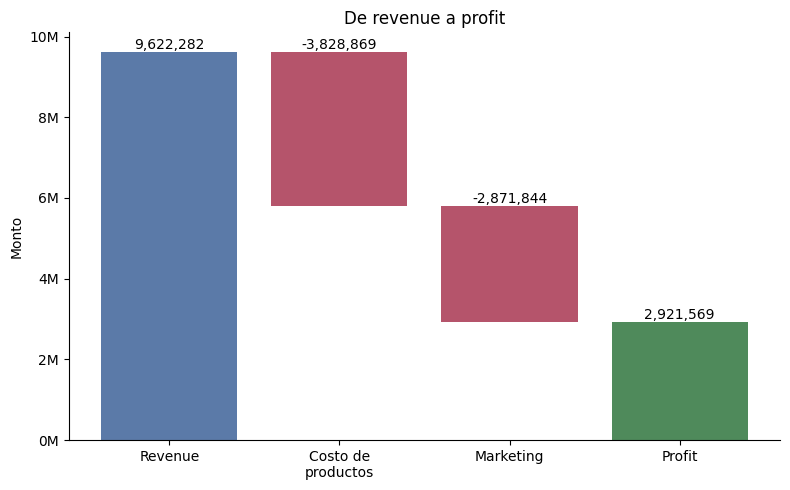

In [ ]:
# Parte 1: Rentabilidad del negocio
# Gráfica de barras de tipo cascada

etiquetas = ['Revenue', 'Costo de\nproductos', 'Marketing', 'Profit']
valores = [revenue, -costo_total, -marketing_total, profit]

# Dónde empieza cada barra
base = [0, revenue - costo_total, revenue - costo_total - marketing_total, 0]
alturas = [revenue, costo_total, marketing_total, profit]
colores = ['#5b7aa8', '#b5546b', '#b5546b', '#4f8a5b']

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(etiquetas, alturas, bottom=base, color=colores)

# Etiquetas con el valor de cada barra
textos = [f'{revenue:,.0f}', f'-{costo_total:,.0f}', f'-{marketing_total:,.0f}', f'{profit:,.0f}']
for barra, texto, b, h in zip(barras, textos, base, alturas):
    ax.text(barra.get_x() + barra.get_width() / 2, b + h, texto,
            ha='center', va='bottom', fontsize=10)

ax.set_title('De revenue a profit')
ax.set_ylabel('Monto')
ax.yaxis.set_major_formatter(lambda x, _: f'{x/1e6:.0f}M')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

# Interpretación: De revenue a profit

La gráfica muestra cómo el ingreso total de **9.62 millones** se reduce hasta llegar a la ganancia final:

- **Costo de productos (3.83 millones, ≈40% del revenue):** es el mayor descuento. Después de pagarlo queda un margen bruto de unos **5.79 millones (≈60%)**.
- **Marketing (2.87 millones, ≈30% del revenue):** es el segundo gasto en importancia y se lleva cerca de la mitad del margen bruto.
- **Profit (2.92 millones, 30.4% del revenue):** es positivo, por lo que **el negocio es rentable**.

**Conclusión:** el negocio genera ganancia, pero el marketing pesa casi tanto como el costo de producción. Cualquier mejora en la eficiencia del gasto publicitario tendría un efecto directo y grande sobre el profit.

*Nota: los pedidos sin producto registrado (≈0.13% del revenue) no tienen costo calculable, así que el costo total está ligeramente subestimado.*

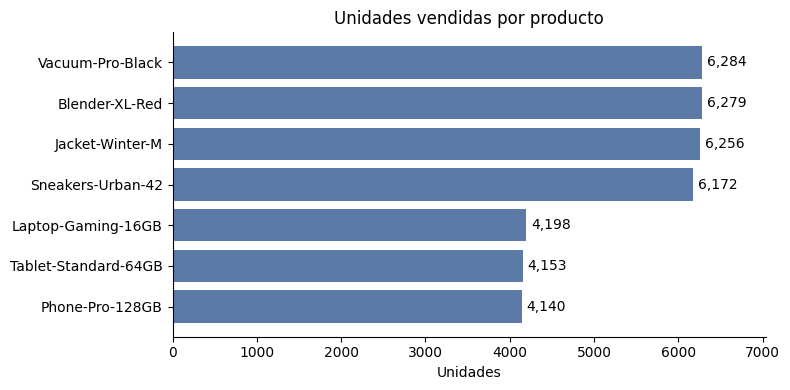

In [ ]:
# Parte 2: Comportamiento de ventas
# Gráfica de barras sobre las unidades vendidas por producto

unidades = (orders[orders['nombre_producto'] != 'Desconocido']
            .groupby('nombre_producto', observed=True)['cantidad'].sum()
            .sort_values())

fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.barh(unidades.index, unidades.values, color='#5b7aa8')

# Etiqueta con el valor al final de cada barra
for barra in barras:
    ax.text(barra.get_width() + 60, barra.get_y() + barra.get_height() / 2,
            f'{barra.get_width():,.0f}', va='center', fontsize=10)

ax.set_title('Unidades vendidas por producto')
ax.set_xlabel('Unidades')
ax.set_xlim(0, unidades.max() * 1.12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

# Interpretación: Producto más vendido

**Vacuum-Pro-Black** es el producto más vendido, con **6,284 unidades**. Sin embargo, no hay un líder claro: Blender-XL-Red (6,279), Jacket-Winter-M (6,256) y Sneakers-Urban-42 (6,172) están a menos de 2% de diferencia. Estos cuatro productos forman el grupo de mayor venta.

Laptop-Gaming-16GB (4,198), Tablet-Standard-64GB (4,153) y Phone-Pro-128GB (4,140) venden alrededor de un tercio menos que el primer grupo.

**Conclusión:** la demanda se concentra en cuatro productos, pero el volumen no basta para decidir qué impulsar. Blender y Jacket venden mucho y dejan márgenes bajos (31% y 26%), mientras que Vacuum-Pro-Black es el más vendido y también el más rentable (margen de 94%).

*Nota: se excluyeron los pedidos sin producto registrado (30 pedidos).*

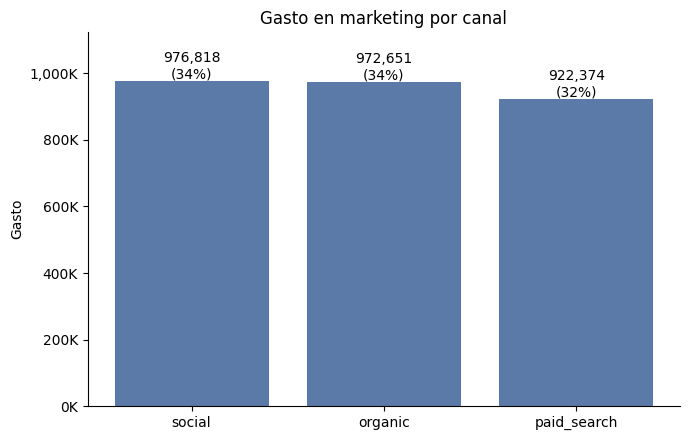

In [ ]:
# Gasto en marketing por canal

gasto_canal = (marketing.groupby('canal', observed=True)['gasto'].sum()
               .sort_values(ascending=False))
porcentajes = gasto_canal / gasto_canal.sum() * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.bar(gasto_canal.index, gasto_canal.values, color='#5b7aa8')

# Etiqueta con el monto y el porcentaje sobre cada barra
for barra, pct in zip(barras, porcentajes):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(),
            f'{barra.get_height():,.0f}\n({pct:.0f}%)',
            ha='center', va='bottom', fontsize=10)

ax.set_title('Gasto en marketing por canal')
ax.set_ylabel('Gasto')
ax.set_ylim(0, gasto_canal.max() * 1.15)
ax.yaxis.set_major_formatter(lambda x, _: f'{x/1e3:,.0f}K')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

# Interpretación: Gasto en marketing por canal

El gasto total en marketing es de **2.87 millones**, repartido casi por igual entre los tres canales:

- **Social:** 976,818 (34%)
- **Organic:** 972,651 (34%)
- **Paid search:** 922,374 (32%)

La diferencia entre el canal con más gasto (social) y el de menos (paid search) es de unos 54,000, cerca de 6%. Entre social y organic la diferencia es mínima (menos de 0.5%).

**Conclusión:** la empresa no prioriza ningún canal: el presupuesto está distribuido de forma pareja. Con estos datos solo se sabe cuánto se gastó en cada canal, no cuánto ingreso generó cada uno. Antes de reasignar presupuesto, conviene medir el retorno por canal (por ejemplo, comparando el gasto con el revenue por `fuente_referencia`).

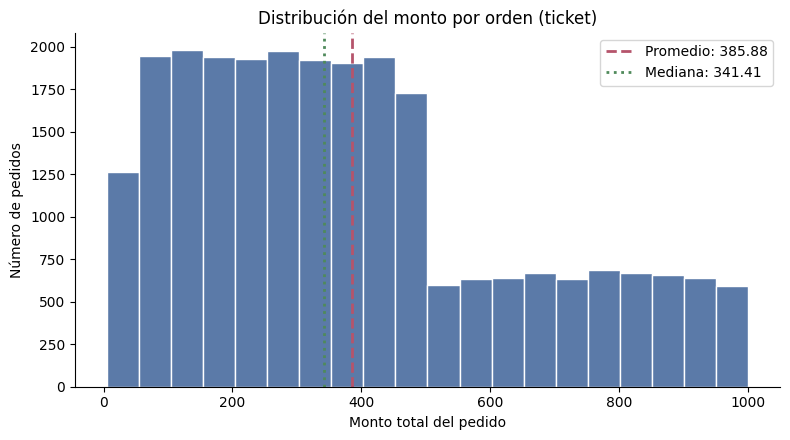

In [ ]:
# Ticket promedio por orden

promedio = orders['monto_total'].mean()
mediana = orders['monto_total'].median()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(orders['monto_total'], bins=20, color='#5b7aa8', edgecolor='white')

ax.axvline(promedio, color='#b5546b', linestyle='--', linewidth=2,
           label=f'Promedio: {promedio:,.2f}')
ax.axvline(mediana, color='#4f8a5b', linestyle=':', linewidth=2,
           label=f'Mediana: {mediana:,.2f}')

ax.set_title('Distribución del monto por orden (ticket)')
ax.set_xlabel('Monto total del pedido')
ax.set_ylabel('Número de pedidos')
ax.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

# Interpretación: Ticket promedio por orden

El **ticket promedio es de 385.88** por orden, y la **mediana es de 341.42**. Como el promedio queda por encima de la mediana, unos pocos pedidos de monto alto lo suben: la mitad de los pedidos está por debajo de 341.

El histograma muestra que no existe un monto "típico":

- Los pedidos de entre unos 50 y 500 se reparten de forma casi pareja, con cerca de 1,900 pedidos por tramo.
- Por encima de 500, la frecuencia baja a cerca de un tercio (unos 600 a 700 pedidos por tramo), pero los montos llegan hasta casi 1,000. Los pedidos de más de 800 son alrededor del 10% del total.
- El monto varía mucho entre pedidos (desviación estándar de 255.69), así que el promedio por sí solo no describe a un cliente típico.

**Conclusión:** el ticket de 385.88 es una referencia útil, pero esconde una gran dispersión. Como cada pedido es de 1 o 2 unidades, el monto depende sobre todo del precio unitario del producto. Para aumentar el ticket convendría revisar qué hace que algunos pedidos superen los 500, en lugar de apuntar a un monto promedio.

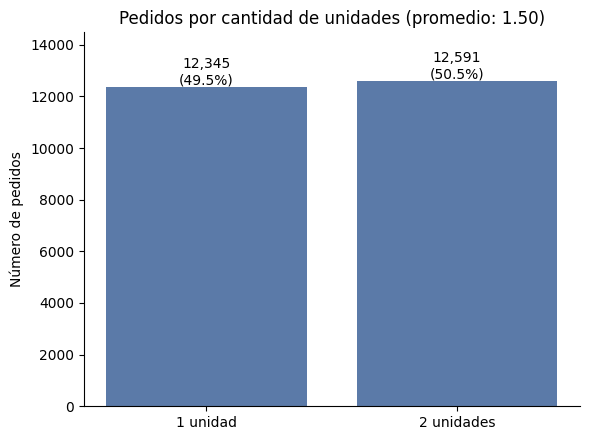

In [ ]:
# Cantidad promedio por orden

conteo = orders['cantidad'].value_counts().sort_index()
promedio = orders['cantidad'].mean()
porcentajes = conteo / conteo.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4.5))
etiquetas = [f'{int(c)} unidad' if c == 1 else f'{int(c)} unidades' for c in conteo.index]
barras = ax.bar(etiquetas, conteo.values, color='#5b7aa8')

# Etiqueta con el número de pedidos y el porcentaje sobre cada barra
for barra, pct in zip(barras, porcentajes):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(),
            f'{barra.get_height():,.0f}\n({pct:.1f}%)',
            ha='center', va='bottom', fontsize=10)

ax.set_title(f'Pedidos por cantidad de unidades (promedio: {promedio:.2f})')
ax.set_ylabel('Número de pedidos')
ax.set_ylim(0, conteo.max() * 1.15)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

# Interpretación: Cantidad promedio por orden

La **cantidad promedio por orden es de 1.50 productos**. La gráfica muestra por qué: los pedidos se reparten casi por igual entre **1 unidad (49.5%)** y **2 unidades (50.5%)**, y no existen pedidos de otra cantidad.

Además, el promedio es prácticamente el mismo en todos los segmentos que revisé (producto, categoría, país, dispositivo y canal de origen), con valores entre 1.49 y 1.52. Es decir, ningún grupo compra más unidades por pedido que otro.

**Conclusión:** la cantidad por pedido no es una palanca para diferenciar productos o mercados. Para aumentar el ingreso por orden habría que probar estrategias que cambien el comportamiento de compra, como paquetes o descuentos por segunda unidad, ya que hoy el cliente compra 1 o 2 unidades sin importar el producto.

---

# 🔹 Paso 3: Entender dónde se pierden los usuarios (funnel de conversión)

**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.


⚙️**Conexión a la base de datos**:  
Se ejecuta la línea de configuración para conectar con la base de datos y aplicar consultas SQL en la tabla **events**.

---

**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  

---

**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel  
- Se identifica en qué etapa se pierde la mayor cantidad de usuarios  
- ¿Cuál es la tasa de conversión final?
---

In [ ]:
import pandas as pd
from sqlalchemy import create_engine

# ======================
# Conexión (NO modificar)
# ======================
db_config = {
    'user': '<usuario>',
    'pwd': '<contraseña>',
    'host': '<host>',
    'port': 5432,
    'db': '<base_de_datos>'
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [ ]:
# Explorar tabla events
# =========================
query_events = '''
SELECT *
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


In [ ]:
# Ver todos los eventos que existen
query_eventos = '''
SELECT nombre_evento,
       COUNT(*) AS filas,
       COUNT(DISTINCT id_usuario) AS usuarios
FROM events
GROUP BY nombre_evento
ORDER BY usuarios DESC;
'''
pd.read_sql(query_eventos, con=engine)

,nombre_evento,filas,usuarios
0,first_visit,29957,7796
1,add_to_cart,24157,7634
2,select_item,23887,7582
3,begin_checkout,17971,7208
4,add_payment_info,12018,6250
5,purchase,12010,6240


In [ ]:
# PARTE 1: Totales del funnel
# ======================

query_totals = '''
SELECT
    CASE nombre_evento
        WHEN 'first_visit'      THEN 1
        WHEN 'select_item'      THEN 2
        WHEN 'add_to_cart'      THEN 3
        WHEN 'begin_checkout'   THEN 4
        WHEN 'add_payment_info' THEN 5
        WHEN 'purchase'         THEN 6
    END AS orden,
    nombre_evento,
    COUNT(DISTINCT id_usuario) AS usuarios
FROM events
WHERE nombre_evento IN ('first_visit', 'select_item', 'add_to_cart',
                        'begin_checkout', 'add_payment_info', 'purchase')
GROUP BY nombre_evento
ORDER BY orden;
'''

totals = pd.read_sql(query_totals, con=engine)
totals

,orden,nombre_evento,usuarios
0,1,first_visit,7796
1,2,select_item,7582
2,3,add_to_cart,7634
3,4,begin_checkout,7208
4,5,add_payment_info,6250
5,6,purchase,6240


In [ ]:
# PARTE 2: Conversiones
# ======================

query_conversion = '''
WITH funnel AS (
    SELECT
        CASE nombre_evento
            WHEN 'first_visit'      THEN 1
            WHEN 'select_item'      THEN 2
            WHEN 'add_to_cart'      THEN 3
            WHEN 'begin_checkout'   THEN 4
            WHEN 'add_payment_info' THEN 5
            WHEN 'purchase'         THEN 6
        END AS orden,
        nombre_evento,
        COUNT(DISTINCT id_usuario) AS usuarios
    FROM events
    WHERE nombre_evento IN ('first_visit', 'select_item', 'add_to_cart',
                            'begin_checkout', 'add_payment_info', 'purchase')
    GROUP BY nombre_evento
)
SELECT
    orden,
    nombre_evento,
    usuarios,
    LAG(usuarios) OVER (ORDER BY orden) - usuarios AS usuarios_perdidos,
    ROUND(100.0 * usuarios / LAG(usuarios) OVER (ORDER BY orden), 2) AS conv_vs_paso_anterior,
    ROUND(100.0 * usuarios / FIRST_VALUE(usuarios) OVER (ORDER BY orden), 2) AS conv_vs_inicio
FROM funnel
ORDER BY orden;
'''

conversion = pd.read_sql(query_conversion, con=engine)
conversion

,orden,nombre_evento,usuarios,usuarios_perdidos,conv_vs_paso_anterior,conv_vs_inicio
0,1,first_visit,7796,NaN,NaN,100.00
1,2,select_item,7582,214.0,97.26,97.26
2,3,add_to_cart,7634,-52.0,100.69,97.92
3,4,begin_checkout,7208,426.0,94.42,92.46
4,5,add_payment_info,6250,958.0,86.71,80.17
5,6,purchase,6240,10.0,99.84,80.04


In [ ]:
# Comprobación
print(conversion.loc[conversion['usuarios_perdidos'].idxmax(), ['nombre_evento', 'usuarios_perdidos']])
print(conversion.loc[conversion['nombre_evento'] == 'purchase', 'conv_vs_inicio'])

nombre_evento        add_payment_info
usuarios_perdidos               958.0
Name: 4, dtype: object
5    80.04
Name: conv_vs_inicio, dtype: float64


In [ ]:
query_totals_estricto = '''
WITH pasos AS (
    SELECT
        id_usuario,
        MAX(CASE WHEN nombre_evento = 'first_visit'      THEN 1 ELSE 0 END) AS p1,
        MAX(CASE WHEN nombre_evento = 'select_item'      THEN 1 ELSE 0 END) AS p2,
        MAX(CASE WHEN nombre_evento = 'add_to_cart'      THEN 1 ELSE 0 END) AS p3,
        MAX(CASE WHEN nombre_evento = 'begin_checkout'   THEN 1 ELSE 0 END) AS p4,
        MAX(CASE WHEN nombre_evento = 'add_payment_info' THEN 1 ELSE 0 END) AS p5,
        MAX(CASE WHEN nombre_evento = 'purchase'         THEN 1 ELSE 0 END) AS p6
    FROM events
    GROUP BY id_usuario
)
SELECT 1 AS orden, 'first_visit'      AS nombre_evento, SUM(p1)                      AS usuarios FROM pasos
UNION ALL
SELECT 2, 'select_item',      SUM(p1*p2)                      FROM pasos
UNION ALL
SELECT 3, 'add_to_cart',      SUM(p1*p2*p3)                   FROM pasos
UNION ALL
SELECT 4, 'begin_checkout',   SUM(p1*p2*p3*p4)                FROM pasos
UNION ALL
SELECT 5, 'add_payment_info', SUM(p1*p2*p3*p4*p5)             FROM pasos
UNION ALL
SELECT 6, 'purchase',         SUM(p1*p2*p3*p4*p5*p6)          FROM pasos
ORDER BY orden;
'''

totals_estricto = pd.read_sql(query_totals_estricto, con=engine)
totals_estricto

,orden,nombre_evento,usuarios
0,1,first_visit,7796
1,2,select_item,7393
2,3,add_to_cart,7052
3,4,begin_checkout,6364
4,5,add_payment_info,4967
5,6,purchase,3857


In [ ]:
query_conversion_estricta = '''
WITH pasos AS (
    SELECT
        id_usuario,
        MAX(CASE WHEN nombre_evento = 'first_visit'      THEN 1 ELSE 0 END) AS p1,
        MAX(CASE WHEN nombre_evento = 'select_item'      THEN 1 ELSE 0 END) AS p2,
        MAX(CASE WHEN nombre_evento = 'add_to_cart'      THEN 1 ELSE 0 END) AS p3,
        MAX(CASE WHEN nombre_evento = 'begin_checkout'   THEN 1 ELSE 0 END) AS p4,
        MAX(CASE WHEN nombre_evento = 'add_payment_info' THEN 1 ELSE 0 END) AS p5,
        MAX(CASE WHEN nombre_evento = 'purchase'         THEN 1 ELSE 0 END) AS p6
    FROM events
    GROUP BY id_usuario
),
funnel AS (
    SELECT 1 AS orden, 'first_visit'      AS nombre_evento, SUM(p1)             AS usuarios FROM pasos
    UNION ALL
    SELECT 2, 'select_item',      SUM(p1*p2)             FROM pasos
    UNION ALL
    SELECT 3, 'add_to_cart',      SUM(p1*p2*p3)          FROM pasos
    UNION ALL
    SELECT 4, 'begin_checkout',   SUM(p1*p2*p3*p4)       FROM pasos
    UNION ALL
    SELECT 5, 'add_payment_info', SUM(p1*p2*p3*p4*p5)    FROM pasos
    UNION ALL
    SELECT 6, 'purchase',         SUM(p1*p2*p3*p4*p5*p6) FROM pasos
)
SELECT
    orden,
    nombre_evento,
    usuarios,
    LAG(usuarios) OVER (ORDER BY orden) - usuarios AS usuarios_perdidos,
    ROUND(100.0 * usuarios / LAG(usuarios) OVER (ORDER BY orden), 2) AS conv_vs_paso_anterior,
    ROUND(100.0 * usuarios / FIRST_VALUE(usuarios) OVER (ORDER BY orden), 2) AS conv_vs_inicio
FROM funnel
ORDER BY orden;
'''

conversion_estricta = pd.read_sql(query_conversion_estricta, con=engine)
conversion_estricta

,orden,nombre_evento,usuarios,usuarios_perdidos,conv_vs_paso_anterior,conv_vs_inicio
0,1,first_visit,7796,NaN,NaN,100.00
1,2,select_item,7393,403.0,94.83,94.83
2,3,add_to_cart,7052,341.0,95.39,90.46
3,4,begin_checkout,6364,688.0,90.24,81.63
4,5,add_payment_info,4967,1397.0,78.05,63.71
5,6,purchase,3857,1110.0,77.65,49.47


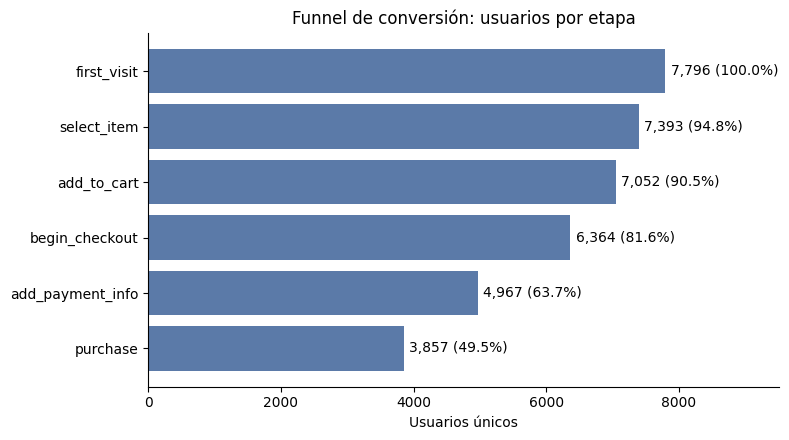

In [ ]:
# Gráfica del funnel (usuarios por etapa)

df_f = conversion_estricta.sort_values('orden', ascending=False)  # first_visit queda arriba

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.barh(df_f['nombre_evento'], df_f['usuarios'], color='#5b7aa8')

# Etiqueta con usuarios y % respecto al inicio
for barra, usuarios, pct in zip(barras, df_f['usuarios'], df_f['conv_vs_inicio']):
    ax.text(barra.get_width() + 80, barra.get_y() + barra.get_height() / 2,
            f'{usuarios:,.0f} ({pct:.1f}%)', va='center', fontsize=10)

ax.set_title('Funnel de conversión: usuarios por etapa')
ax.set_xlabel('Usuarios únicos')
ax.set_xlim(0, df_f['usuarios'].max() * 1.22)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

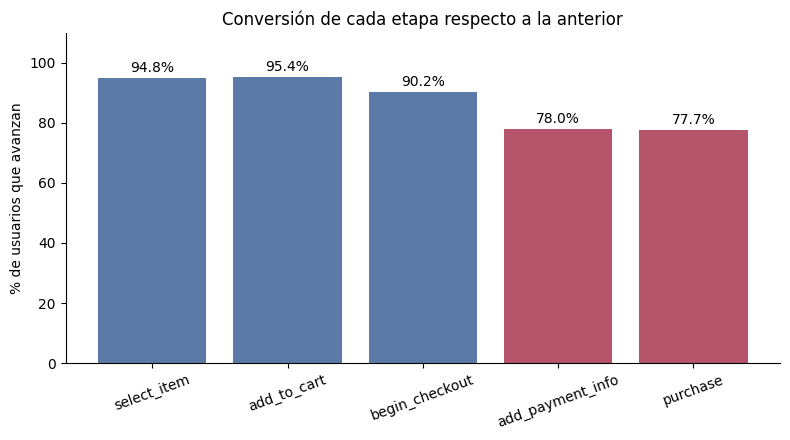

In [ ]:
# Gráfica de conversión entre pasos

# Sin la primera fila (first_visit no tiene paso anterior)
df_c = conversion_estricta.dropna(subset=['conv_vs_paso_anterior'])

# Rojo para los pasos con conversión menor a 80%, azul para el resto
colores = ['#b5546b' if v < 80 else '#5b7aa8' for v in df_c['conv_vs_paso_anterior']]

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(df_c['nombre_evento'], df_c['conv_vs_paso_anterior'], color=colores)

for barra, v in zip(barras, df_c['conv_vs_paso_anterior']):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 1,
            f'{v:.1f}%', ha='center', va='bottom', fontsize=10)

ax.set_title('Conversión de cada etapa respecto a la anterior')
ax.set_ylabel('% de usuarios que avanzan')
ax.set_ylim(0, 110)
plt.xticks(rotation=20)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

# Primera versión del análisis del Funnel de conversión: alcance por evento (no es un funnel secuencial; ver corrección más abajo)

**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  

- - `first_visit`: 7,796
- - `select_item`: 7,582
- - `add_to_cart`: 7,634
- - `begin_checkout`: 7,208
- - `add_payment_info`:	6,250
- - `purchase`:	6,240


---

**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel

- - `first_visit`: NaN
- - `select_item`: 97.26%
- - `add_to_cart`: 100.69%
- - `begin_checkout`: 94.42%
- - `add_payment_info`: 86.71%
- - `purchase`:	99.84%


- Se identifica en qué etapa se pierde la mayor cantidad de usuarios

De los 7,208 usuarios que iniciaron el checkout, sólo 6,250 agregaron su pago, es decir una tasa de conversión del 86.71%.

- ¿Cuál es la tasa de conversión final?

80.04% (6,240 de 7,796 usuarios llegan de la primera visita a la compra).

**Insights**

- El funnel muestra una retención alta en todas las etapas. La mayor fuga ocurre en el checkout, entre el inicio de la compra y el ingreso de la información de pago, donde se pierden 958 usuarios (13.3%). Una vez que el usuario ingresa su información de pago, casi todos completan la compra (99.84%). La conversión final de primera visita a compra es de 80.04%. Esto sugiere que la prioridad de mejora está en simplificar el paso de pago.

- `add_to_cart` tiene más usuarios que `select_item`, lo que da una conversión mayor a 100% en ese paso. Ocurre porque se cuentan usuarios únicos por evento sin verificar que hayan pasado por el paso anterior.
Una conversión de 80% es inusualmente alta para un funnel real, lo que sugiere que los datos son sintéticos.

# Interpretación: Funnel estricto de conversión

**Corrección del cálculo.** En la primera versión se contaban usuarios únicos por evento sin exigir que hubieran pasado por los pasos anteriores, y eso producía una conversión de 100.69% en `add_to_cart`, algo imposible en un funnel. Se corrigió con un **funnel estricto**: un usuario cuenta en una etapa solo si también hizo todas las anteriores. Con esto el número de usuarios baja en cada paso y ninguna tasa supera el 100%.

**Resultados del funnel estricto:**

- De **7,796** usuarios que visitan por primera vez, solo **3,857 (49.47%)** llegan a comprar. Esta es la **tasa de conversión final**.
- Las etapas iniciales retienen bien: `select_item` (94.83%), `add_to_cart` (95.39%) y `begin_checkout` (90.24%) convierten más del 90% respecto al paso anterior.
- La mayor pérdida está entre `begin_checkout` y `add_payment_info`: se pierden **1,397 usuarios**, el 22% de quienes iniciaron el checkout. Esa etapa concentra cerca de un tercio de todos los usuarios perdidos en el funnel (1,397 de 3,939).
- El último paso también es débil: de los usuarios que agregan su información de pago, el **77.65%** completa la compra y se pierden otros 1,110.

**Conclusión:** el problema está en el **checkout**, no en la navegación. Hasta que el usuario inicia el pago, la conversión es alta, pero entre el inicio del checkout y la compra se pierde cerca de 40% de los usuarios (6,364 a 3,857). La prioridad de mejora es simplificar el proceso de pago, revisando por ejemplo los pasos de ingreso de datos y los métodos de pago disponibles.

**Comparación con el cálculo anterior.** La versión sin restricción daba una conversión final de 80.04% (6,240 compradores). La diferencia indica que unos 2,400 usuarios aparecían en `purchase` sin haber registrado todos los pasos previos. Es un resultado que conviene revisar con el equipo de datos, porque puede deberse a eventos que no se registran siempre.

**Limitaciones:** el funnel estricto exige haber hecho los pasos previos, pero no verifica que fueran en orden cronológico, porque `timestamp_evento` solo tiene la fecha y no la hora.

---

# 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)

**🎯 Objetivo:** Analizar la retención de usuarios para entender si regresan después de registrarse.

**Tablas**

- `users`
- `user_activity`

---
1. Se identifica la cohorte de cada usuario según el **mes de registro**.


2. Se calcula la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  


3. Se calcula el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  

Se revisa que la columna de fecha esté en formato correcto (`DATE`).  
Se realiza la conversión usando: `CAST(fecha_registro AS DATE)`

In [ ]:
# Explorar tabla users
# =========================
query_users = '''
SELECT *
FROM users;
'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free


In [ ]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''
SELECT *
FROM user_activity;
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1


In [ ]:
# Revisar que la fecha sea tipo DATE
print(users.dtypes)
print(user_activity.dtypes)

id_usuario        object
fecha_registro    object
país              object
dispositivo       object
tipo_plan         object
dtype: object
id_usuario               object
fecha_actividad          object
dias_despues_registro     int64
activo                    int64
dtype: object


In [ ]:
# Revisar qué valores toma 'dias_despues_registro'
pd.read_sql('''
SELECT dias_despues_registro, COUNT(*) AS filas
FROM user_activity
GROUP BY dias_despues_registro
ORDER BY dias_despues_registro;
''', con=engine)

,dias_despues_registro,filas
0,7,8000
1,14,8000
2,21,8000
3,28,8000


In [ ]:
# Retención por cohortes
# ======================

query_cohort_retention_final = '''
WITH retencion AS (
    SELECT
        TO_CHAR(DATE_TRUNC('month', CAST(u.fecha_registro AS DATE)), 'YYYY-MM') AS cohorte,
        COUNT(DISTINCT u.id_usuario) AS usuarios_iniciales,
        COUNT(DISTINCT CASE WHEN a.dias_despues_registro = 7  AND a.activo = 1
                            THEN u.id_usuario END) AS retenido_w1,
        COUNT(DISTINCT CASE WHEN a.dias_despues_registro = 14 AND a.activo = 1
                            THEN u.id_usuario END) AS retenido_w2,
        COUNT(DISTINCT CASE WHEN a.dias_despues_registro = 21 AND a.activo = 1
                            THEN u.id_usuario END) AS retenido_w3
    FROM users u
    LEFT JOIN user_activity a
           ON u.id_usuario = a.id_usuario
    GROUP BY 1
)
SELECT
    cohorte,
    usuarios_iniciales,
    retenido_w1,
    retenido_w2,
    retenido_w3,
    ROUND(100.0 * retenido_w1 / usuarios_iniciales, 2) AS semana_1,
    ROUND(100.0 * retenido_w2 / usuarios_iniciales, 2) AS semana_2,
    ROUND(100.0 * retenido_w3 / usuarios_iniciales, 2) AS semana_3
FROM retencion
ORDER BY cohorte;
'''

# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final

,cohorte,usuarios_iniciales,retenido_w1,retenido_w2,retenido_w3,semana_1,semana_2,semana_3
0,2025-01,1627,697,668,656,42.84,41.06,40.32
1,2025-02,1444,611,609,635,42.31,42.17,43.98
2,2025-03,1636,677,705,690,41.38,43.09,42.18
3,2025-04,1606,680,697,663,42.34,43.40,41.28
4,2025-05,1687,695,676,706,41.20,40.07,41.85


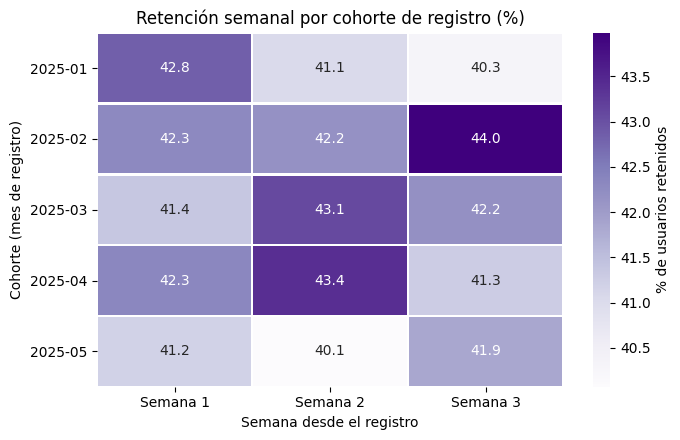

In [ ]:
# Mapa de calor de la retención

datos = cohorte_final.set_index('cohorte')[['semana_1', 'semana_2', 'semana_3']]
datos.columns = ['Semana 1', 'Semana 2', 'Semana 3']

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(datos, annot=True, fmt='.1f', cmap='Purples',
            linewidths=1, linecolor='white',
            cbar_kws={'label': '% de usuarios retenidos'}, ax=ax)

ax.set_title('Retención semanal por cohorte de registro (%)')
ax.set_xlabel('Semana desde el registro')
ax.set_ylabel('Cohorte (mes de registro)')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Interpretación: Retención semanal por cohorte

El mapa de calor muestra el porcentaje de usuarios activos en las semanas 1, 2 y 3 después del registro, para cada cohorte de enero a mayo de 2025. Cuanto más oscuro el morado, mayor la retención.

**Semana más fuerte y más débil de cada cohorte:**

| Cohorte | Semana más fuerte | Semana más débil |
|---|---|---|
| 2025-01 | Semana 1 (42.84%) | Semana 3 (40.32%) |
| 2025-02 | Semana 3 (43.98%) | Semana 2 (42.17%) |
| 2025-03 | Semana 2 (43.09%) | Semana 1 (41.38%) |
| 2025-04 | Semana 2 (43.40%) | Semana 3 (41.28%) |
| 2025-05 | Semana 3 (41.85%) | Semana 2 (40.07%) |

**Lo que se observa:**

- La celda más fuerte es la **cohorte 2025-02 en la semana 3 (43.98%)** y la más débil es la **cohorte 2025-05 en la semana 2 (40.07%)**.
- La **cohorte 2025-02** es la de mejor retención en promedio (unos 42.8%) y la **2025-05** la más baja (unos 41.0%).
- **No hay una semana ganadora:** el promedio de las cinco cohortes es casi igual en las tres semanas (42.0%, 42.0% y 41.9%). Solo la cohorte de enero muestra una caída continua (de 42.84% a 40.32%); en las demás la retención sube y baja de una semana a otra.
- **No se ve un deterioro entre cohortes:** las cohortes más recientes no retienen peor que las primeras.

**Conclusión:** la retención es estable, entre 40% y 44% en todas las cohortes y semanas. La diferencia entre la celda más fuerte y la más débil es de unos 4 puntos, y el contraste del color la hace parecer mayor de lo que es. Con cohortes de entre 1,400 y 1,700 usuarios, diferencias de uno o dos puntos pueden deberse al azar. El hallazgo principal es que **cerca de 6 de cada 10 usuarios no están activos desde la semana 1**, y no se recuperan después. El reto está en la activación temprana, no en una semana o cohorte en particular.

*Nota: cada porcentaje cuenta a los usuarios activos en esa semana específica, no a los que estuvieron activos en todas las semanas anteriores. Por eso un valor puede subir de una semana a la siguiente.*

In [ ]:
# Revisar
users.dtypes

id_usuario        object
fecha_registro    object
país              object
dispositivo       object
tipo_plan         object
dtype: object

In [ ]:
len(users)

8000

In [ ]:
# Conversión de la columna 'fecha_registro' a tipo DATE
query_check_fecha = '''
SELECT
    fecha_registro,
    CAST(fecha_registro AS DATE) AS fecha_registro_date
FROM users
LIMIT 5;
'''
pd.read_sql(query_check_fecha, con=engine)

,fecha_registro,fecha_registro_date
0,2025-01-29,2025-01-29
1,2025-01-07,2025-01-07
2,2025-03-12,2025-03-12
3,2025-03-04,2025-03-04
4,2025-02-27,2025-02-27


**Insights**

- La retención es estable, de 40% a 44%. En todas las cohortes, entre 4 y 6 de cada 10 usuarios siguen activos en cada semana.
- No hay una caída clara de la semana 1 a la 3. En enero baja un poco (42.84% → 40.32%), pero en febrero sube (42.31% → 43.98%). Las diferencias son de pocos puntos, así que no hay una cohorte claramente mejor ni peor.
- Valores extremos: el más alto es febrero en la semana 3 (43.98%) y el más bajo es mayo en la semana 2 (40.07%).

**Insight de retención**

- La retención semanal se mantiene estable entre las cohortes de enero a mayo de 2025, con valores de 40% a 44% en las semanas 1, 2 y 3. No se observa un deterioro entre cohortes ni una caída marcada a lo largo de las semanas. Aproximadamente el 60% de los usuarios deja de estar activo desde la primera semana, y ese grupo no se recupera de forma notable. El principal reto es entonces la activación temprana: lograr que más usuarios sigan activos desde la semana 1.

---

# 🔹 Paso 5: Validar si los cambios generan impacto (test estadístico)

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.

---

1. **Analizar el dataset** `experiment_checkout_ui.csv` para identificar la métrica principal **conversion**.
   - La métrica **conversion** es 1 si el usuario completó la compra, 0 si no.    
2. **Plantear la hipótesis estadística**     
3. **Aplicar el test estadístico adecuado**
4. **Interpretar el resultado**  

In [ ]:
# 1: Explorar el dataset
df = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv')

df.head()
df.info()
print(df['convirtio'].value_counts(dropna=False))
print(df['variante'].value_counts(dropna=False))
print(df.isna().sum())
print('Duplicados exactos:', df.duplicated().sum())
print('Usuarios repetidos:', df['id_usuario'].duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_usuario       10000 non-null  object 
 1   variante         10000 non-null  object 
 2   convirtio        10000 non-null  int64  
 3   dispositivo      10000 non-null  object 
 4   pais             10000 non-null  object 
 5   duracion_sesion  10000 non-null  float64
 6   timestamp        10000 non-null  object 
dtypes: float64(1), int64(1), object(5)
memory usage: 547.0+ KB
0    8401
1    1599
Name: convirtio, dtype: int64
tratamiento    5035
control        4965
Name: variante, dtype: int64
id_usuario         0
variante           0
convirtio          0
dispositivo        0
pais               0
duracion_sesion    0
timestamp          0
dtype: int64
Duplicados exactos: 0
Usuarios repetidos: 0


In [ ]:
# Explorar la métrica principal: la tasa de conversión por variante
resumen = df.groupby('variante')['convirtio'].agg(usuarios='count', compras='sum', tasa='mean')
print(resumen)

             usuarios  compras      tasa
variante                                
control          4965      779  0.156898
tratamiento      5035      820  0.162860


In [ ]:
# 2: Hipótesis estadística

Sea `p_control` la conversión del checkout original y `p_tratamiento` la del nuevo diseño:

**H₀: p_tratamiento = p_control (la nueva UI no cambia la tasa de conversión).**

**H₁: p_tratamiento ≠ p_control (la nueva UI sí la cambia).**

Nivel de significancia `α = 0.05`, prueba de dos colas, porque interesa detectar tanto una mejora como un empeoramiento.

La conversión es binaria y compara dos grupos independientes, así que el test adecuado es la prueba z de proporciones (z-test).

In [ ]:
# 3: Test estadístico
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

control = df[df['variante'] == 'control']['convirtio']
tratamiento = df[df['variante'] == 'tratamiento']['convirtio']

compras = [tratamiento.sum(), control.sum()]
usuarios = [len(tratamiento), len(control)]

z, p_valor = proportions_ztest(compras, usuarios, alternative='two-sided')

diferencia = tratamiento.mean() - control.mean()
ic = confint_proportions_2indep(
    tratamiento.sum(), len(tratamiento), control.sum(), len(control)
)

print(f"Conversión control:     {control.mean():.2%}")
print(f"Conversión tratamiento: {tratamiento.mean():.2%}")
print(f"Diferencia:             {diferencia:.2%}")
print(f"z = {z:.3f} | p-valor = {p_valor:.4f}")
print(f"IC 95% de la diferencia: [{ic[0]:.2%}, {ic[1]:.2%}]")

Conversión control:     15.69%
Conversión tratamiento: 16.29%
Diferencia:             0.60%
z = 0.813 | p-valor = 0.4161
IC 95% de la diferencia: [-0.84%, 2.03%]


In [ ]:
# 4: Interpretar el resultado

**Interpretación de los resultados**

- La tasa de conversión fue de 15.69% en el grupo control y 16.29% en el grupo tratamiento, una diferencia de 0.60 puntos porcentuales. El z-test arrojó z = 0.813 y p = 0.4161, mayor que α = 0.05, por lo que no se rechaza la hipótesis nula. El intervalo de confianza al 95% de la diferencia, [-0.84%, 2.03%], incluye el cero. Por lo tanto, no hay evidencia estadística de que la modificación en la UI del checkout impacte la tasa de conversión. La mejora observada en la muestra es compatible con el azar.

**Recomendación**

- Con unos 5,000 usuarios por grupo, el experimento solo detecta diferencias bastante grandes (el IC llega a ±1.4 puntos), así que un efecto pequeño real podría haber pasado desapercibido. Se podría repetir con una muestra mayor si el negocio considera relevante una mejora de menos de 1 punto.

---

# 🔹 Paso 6: Comunicar los resultados (Dashboard en BI)

🎯 **Objetivo**:  
Crear un dashboard que muestre de manera clara y visual los resultados del análisis de ventas, costos, marketing y conversión.

Se usarán los CSVs limpios del Paso 1:

- `orders_clean.csv`  
- `catalog_clean.csv`  
- `marketing_clean.csv`

---

1️⃣ Preparación de los datos
1. Cargar los CSVs en Power BI o Tableau.
2. Revisar relaciones:
   - `orders.nombre_producto` → `catalog.nombre_producto`
   - `orders.fecha_pedido` → tabla de fechas (crear calendario para análisis temporal)
   - `orders.fecha_pedido` → `dim_fecha.date`
3. Crear columnas calculadas necesarias
4. Crear tabla de fechas para poder calcular comparaciones YTD, YoY o períodos anteriores (`Previous Year`, `Previous Month`).

---

2️⃣ Dashboard 1: Overview Ejecutivo
**KPIs principales a mostrar:**
- Revenue total
- Profit total
- Gasto total en marketing
- Ticket promedio
- Cantidad promedio de productos por orden

**Visualizaciones sugeridas:**
- Tarjetas KPI para revenue, profit y gasto marketing
- Gráfico de líneas: evolución mensual de revenue o profit
- Gráfico de líneas YTD
- Gráfico de barras: revenue y profit por producto o categoría

---

 3️⃣ Dashboard 2: Detalle / Drill-through  
**Objetivo:** Permitir explorar los datos desde el KPI general hasta cada orden o producto.

**Visualizaciones sugeridas:**
- Tabla detallada de órdenes con:
  - producto, cantidad, revenue, cost, profit
  - color condicional (profit negativo en rojo, positivo en verde)
- Gráfico de barras por producto con medida `cantidad vendida`
- Drill-through: seleccionar un producto y ver todos los pedidos relacionados
- Filtros por fecha, categoría de producto, etc

In [ ]:
# Crear dim_fecha para poder crear una tabla de fechas para Tableau
dim_fecha = pd.DataFrame({'date': pd.date_range('2025-01-01', '2025-06-30', freq='D')})

dim_fecha['año'] = dim_fecha['date'].dt.year
dim_fecha['mes_num'] = dim_fecha['date'].dt.month
dim_fecha['mes'] = dim_fecha['date'].dt.strftime('%Y-%m')
dim_fecha['trimestre'] = dim_fecha['date'].dt.quarter
dim_fecha['semana'] = dim_fecha['date'].dt.isocalendar().week
dim_fecha['dia_semana'] = dim_fecha['date'].dt.day_name()

print(dim_fecha.shape)
dim_fecha.head()

(181, 7)


,date,año,mes_num,mes,trimestre,semana,dia_semana
0,2025-01-01,2025,1,2025-01,1,1,Wednesday
1,2025-01-02,2025,1,2025-01,1,1,Thursday
2,2025-01-03,2025,1,2025-01,1,1,Friday
3,2025-01-04,2025,1,2025-01,1,1,Saturday
4,2025-01-05,2025,1,2025-01,1,1,Sunday


In [ ]:
# Exportación y comprobación
dim_fecha.to_csv('dim_fecha.csv', index=False)
pd.read_csv('dim_fecha.csv').head(3)

,date,año,mes_num,mes,trimestre,semana,dia_semana
0,2025-01-01,2025,1,2025-01,1,1,Wednesday
1,2025-01-02,2025,1,2025-01,1,1,Thursday
2,2025-01-03,2025,1,2025-01,1,1,Friday


In [ ]:
# Preparar la fecha de orders
orders_csv = pd.read_csv('orders_clean.csv')
orders_csv['fecha_hora_pedido'].head(3)

0    2025-05-22 00:00:00+00:00
1    2025-06-15 00:00:00+00:00
2    2025-05-02 00:00:00+00:00
Name: fecha_hora_pedido, dtype: object

In [ ]:
# Crear fecha_pedido
orders['fecha_pedido'] = orders['fecha_hora_pedido'].dt.strftime('%Y-%m-%d')

orders[['fecha_hora_pedido', 'fecha_pedido']].head(3)

,fecha_hora_pedido,fecha_pedido
0,2025-05-22 00:00:00+00:00,2025-05-22
1,2025-06-15 00:00:00+00:00,2025-06-15
2,2025-05-02 00:00:00+00:00,2025-05-02


In [ ]:
# Re-exportar orders
orders.to_csv('orders_clean.csv', index=False)
pd.read_csv('orders_clean.csv').shape

(24936, 14)

In [ ]:
# EXTRA: Exportar archivo .csv del funnel

conversion_estricta.to_csv('funnel_estricto.csv', index=False)
pd.read_csv('funnel_estricto.csv')


,orden,nombre_evento,usuarios,usuarios_perdidos,conv_vs_paso_anterior,conv_vs_inicio
0,1,first_visit,7796,NaN,NaN,100.00
1,2,select_item,7393,403.0,94.83,94.83
2,3,add_to_cart,7052,341.0,95.39,90.46
3,4,begin_checkout,6364,688.0,90.24,81.63
4,5,add_payment_info,4967,1397.0,78.05,63.71
5,6,purchase,3857,1110.0,77.65,49.47


---

# 🚀 Entrega Final

Comparte el acceso a tu Dashboard para revisión.   
Puedes entregar el Dashboard utilizando **Power BI o Tableau**.

Incluye **uno de los siguientes**:

- 🔗 Link público del dashboard publicado en **Power BI Service o Tableau Public / Tableau Cloud**
- 🔗 Link de **Google Drive o OneDrive** con el archivo del proyecto (`.pbix`) y los 3 csvs limpios.


### 📎 Enlace del Dashboard

# link de power bi o tableau
https://public.tableau.com/views/Dashboard_RappiPlus/OverviewEjecutivo?:language=en-US&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link

# Conclusiones y recomendaciones generales

# Conclusiones

1. **El negocio es rentable, pero el marketing pesa mucho.** De 9.62 millones de revenue quedan 2.92 millones de profit (30.4%). El costo de productos consume cerca del 40% del ingreso y el marketing cerca del 30%.
2. **Vender más no significa ganar más.** Vacuum-Pro-Black es el producto más vendido y el más rentable, pero Blender y Jacket venden casi lo mismo con márgenes de solo 31% y 26%, y Laptop-Gaming-16GB se vende a pérdida (−93,622).
3. **El principal punto de fuga es el checkout.** En el funnel estricto, 49.47% de los usuarios llega a comprar. La mayor pérdida ocurre entre el inicio del checkout y el ingreso de la información de pago (1,397 usuarios, 22%).
4. **La retención es estable pero baja.** Entre 40% y 44% de los usuarios sigue activo en cada una de las semanas 1 a 3, en todas las cohortes. Cerca de 6 de cada 10 no están activos desde la primera semana.
5. **El cambio de UI del checkout no mostró un efecto detectable.** La conversión fue de 15.69% en control y 16.29% en tratamiento, una diferencia de 0.6 puntos que no es estadísticamente significativa (p = 0.4161). Esto no prueba que la nueva UI sea igual a la anterior: con unos 5,000 usuarios por grupo, el experimento solo detecta mejoras de alrededor de 2 puntos o más, y un efecto menor podría haber pasado desapercibido.

# Recomendaciones

1. **Revisar el precio o el costo de la Laptop-Gaming-16GB** y los márgenes de Blender y Jacket, antes de seguir impulsando su venta.
2. **Priorizar la mejora del proceso de pago**, que es donde se concentra la mayor pérdida de usuarios: simplificar los pasos, revisar los métodos de pago y la información que se pide.
3. **Medir el retorno de cada canal de marketing** (revenue generado por canal contra gasto) antes de reasignar presupuesto, porque hoy el gasto está repartido casi por igual y solo se sabe cuánto se invirtió.
4. **Reforzar la activación temprana**, con acciones en la primera semana después del registro, ya que ahí se pierde la mayor parte de los usuarios y casi no se recuperan.
5. **Repetir el experimento del checkout con una muestra mayor**, o probar un cambio más ambicioso, porque este resultado no permite concluir si la nueva UI ayuda o no.
6. **Revisar el registro de eventos con el equipo de datos.** Cerca de 2,400 usuarios aparecían en `purchase` sin haber registrado todos los pasos previos, lo que apunta a eventos que no siempre se guardan.
